# Compare test submissions by eye

There is no ground truth for test, so this notebook shows what the submissions **do differently** on the test frames, with a focus on the low-resolution clips (680 and 960 px wide), where objects are tiniest.

- **Section 2:** the main submissions side by side on the low-resolution frames where they disagree most. Every submission shows the **same number of boxes** over the whole test set (its own score threshold, matched to the reference's box count at score ≥ `REF_THR`), so the panels compare rankings, not thresholds. A **thick** box is one the reference does not have (no same-class box with IoU ≥ 0.5).
- **Section 3:** every available submission on one frame.
- **Section 4:** numbers for all submissions: boxes per frame, share of small boxes, class mix, how much each pair agrees, and the leaderboard score where known.

CPU only, a few minutes (parsing the CSVs). Images are saved to `outputs/compare/`.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw

ROOT = Path.cwd().parent.parent    # this notebook lives in src/experiments/
DATA_ROOT = ROOT / "multiple-object-video-detection-hw-2-ucu-ai-2026"
RUNS = ROOT / "runs"
OUT_DIR = ROOT / "outputs" / "compare"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

# name: (CSV, public leaderboard score if submitted). Missing files are skipped.
CANDIDATES = {
    "FRCNN multi-scale":            (RUNS / "faster_rcnn/baseline/submissions/ms.csv", 0.24891),
    "FRCNN multi-scale + temporal": (RUNS / "faster_rcnn/baseline/submissions/ms_temporal.csv", None),
    "A: B's 7":                     (RUNS / "ensemble/submissions/A_b_ensemble.csv", None),
    "B7 + RetinaNet":               (RUNS / "ensemble/submissions/B_best_ensemble.csv", None),
    "B7 + RetinaNet + temporal":    (RUNS / "ensemble/submissions/C_best_temporal.csv", None),
    "B7 + RetinaNet weighted":      (RUNS / "ensemble/submissions/W_best_weighted.csv", None),
    "Person B's pipeline (09)":     (RUNS / "pipeline/submission.csv", None),
}
SUBS = {n: v for n, v in CANDIDATES.items() if v[0].exists()}
REFERENCE = "B7 + RetinaNet"                                                   # thick boxes = not in this one
MAIN = ["B7 + RetinaNet", "B7 + RetinaNet + temporal", "B7 + RetinaNet weighted"]   # section 2
MAIN = [n for n in MAIN if n in SUBS]
if REFERENCE not in SUBS:
    REFERENCE = MAIN[0] if MAIN else next(iter(SUBS))
REF_THR = 0.3          # the reference shows its boxes with score >= REF_THR; the others show as many boxes in total
print("available:", list(SUBS), "| reference:", REFERENCE)

test = pd.read_csv(DATA_ROOT / "test_images.csv")
clip_res = test.groupby("clip")[["width", "height"]].first()
print(clip_res.value_counts().sort_index().to_string())

available: ['FRCNN multi-scale', 'FRCNN multi-scale + temporal', "A: B's 7", 'B7 + RetinaNet', 'B7 + RetinaNet + temporal', 'B7 + RetinaNet weighted'] | reference: B7 + RetinaNet
width  height
680    382        3
960    540        5
1344   756        7
1360   764       18
1904   1072       4
1920   1080      11


## 1. Read the submissions

Each CSV row is `image_id, "class score x y w h ..."`. Boxes are kept as arrays per frame.

In [2]:
def read_submission(path):
    sub = pd.read_csv(path).fillna("")
    out = {}
    for k, s in zip(sub["image_id"], sub["PredictionString"]):
        a = np.array(s.split(), dtype=float).reshape(-1, 6) if s else np.zeros((0, 6))
        out[k] = a          # columns: class, score, x, y, w, h
    return out


preds = {}
for name, (path, _) in SUBS.items():
    preds[name] = read_submission(path)
    print(f"{name}: {sum(len(v) for v in preds[name].values())} boxes")

# Per-submission score threshold giving the same total number of boxes as the reference at REF_THR
n_ref = int(sum((v[:, 1] >= REF_THR).sum() for v in preds[REFERENCE].values()))
THR = {}
for name, p in preds.items():
    s = np.sort(np.concatenate([v[:, 1] for v in p.values()]))[::-1]
    THR[name] = float(s[min(n_ref, len(s)) - 1])
print(f"{n_ref} boxes shown per submission over the test set; thresholds:", {k: round(v, 3) for k, v in THR.items()})

FRCNN multi-scale: 1589606 boxes
FRCNN multi-scale + temporal: 1589606 boxes
A: B's 7: 1905500 boxes
B7 + RetinaNet: 1905500 boxes
B7 + RetinaNet + temporal: 1905500 boxes
B7 + RetinaNet weighted: 1905500 boxes
157600 boxes shown per submission over the test set; thresholds: {'FRCNN multi-scale': 0.745, 'FRCNN multi-scale + temporal': 0.743, "A: B's 7": 0.308, 'B7 + RetinaNet': 0.3, 'B7 + RetinaNet + temporal': 0.31, 'B7 + RetinaNet weighted': 0.307}


In [3]:
def shown(name, image_id):
    a = preds[name].get(image_id, np.zeros((0, 6)))
    return a[a[:, 1] >= THR[name]]


def iou_xywh(a, b):
    ax2, ay2, bx2, by2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = (np.minimum(ax2[:, None], bx2[None]) - np.maximum(a[:, None, 0], b[None, :, 0])).clip(0)
    ih = (np.minimum(ay2[:, None], by2[None]) - np.maximum(a[:, None, 1], b[None, :, 1])).clip(0)
    inter = iw * ih
    return inter / ((a[:, 2] * a[:, 3])[:, None] + (b[:, 2] * b[:, 3])[None] - inter + 1e-9)


def matched(a, b, thr=0.5):
    # For each box in a: is there a box of the same class in b with IoU >= thr?
    out = np.zeros(len(a), bool)
    for c in np.unique(a[:, 0]):
        ia, ib = np.where(a[:, 0] == c)[0], np.where(b[:, 0] == c)[0]
        if len(ib):
            out[ia] = (iou_xywh(a[ia, 2:], b[ib, 2:]) >= thr).any(1)
    return out


COLOURS = [(255, 80, 80), (255, 170, 0), (60, 200, 255), (80, 255, 120), (200, 120, 255), (255, 255, 0), (255, 120, 200), (0, 255, 220)]


def draw(name, image_id, scale):
    row = test.set_index("image_id").loc[image_id]
    img = Image.open(DATA_ROOT / row["file_name"]).convert("RGB")
    img = img.resize((img.width * scale, img.height * scale), Image.LANCZOS)
    d = ImageDraw.Draw(img)
    boxes = shown(name, image_id)
    new = ~matched(boxes, shown(REFERENCE, image_id)) if name != REFERENCE else np.zeros(len(boxes), bool)
    for (c, s, x, y, w, h), is_new in zip(boxes, new):
        d.rectangle([x * scale, y * scale, (x + w) * scale, (y + h) * scale], outline=COLOURS[int(c)], width=5 if is_new else 2)
    return img, len(boxes), int(new.sum())

## 2. Main submissions on the low-resolution clips

For each low-resolution clip, the frame where the main submissions disagree most with the reference. Frames are upscaled ×2 (×1 for 960 px) so small boxes are visible. Colours are classes (legend below); thick boxes are not in the reference.

legend: person=#ff5050, bicycle=#ffaa00, car=#3cc8ff, van=#50ff78, truck=#c878ff, tricycle=#ffff00, bus=#ff78c8, motor=#00ffdc


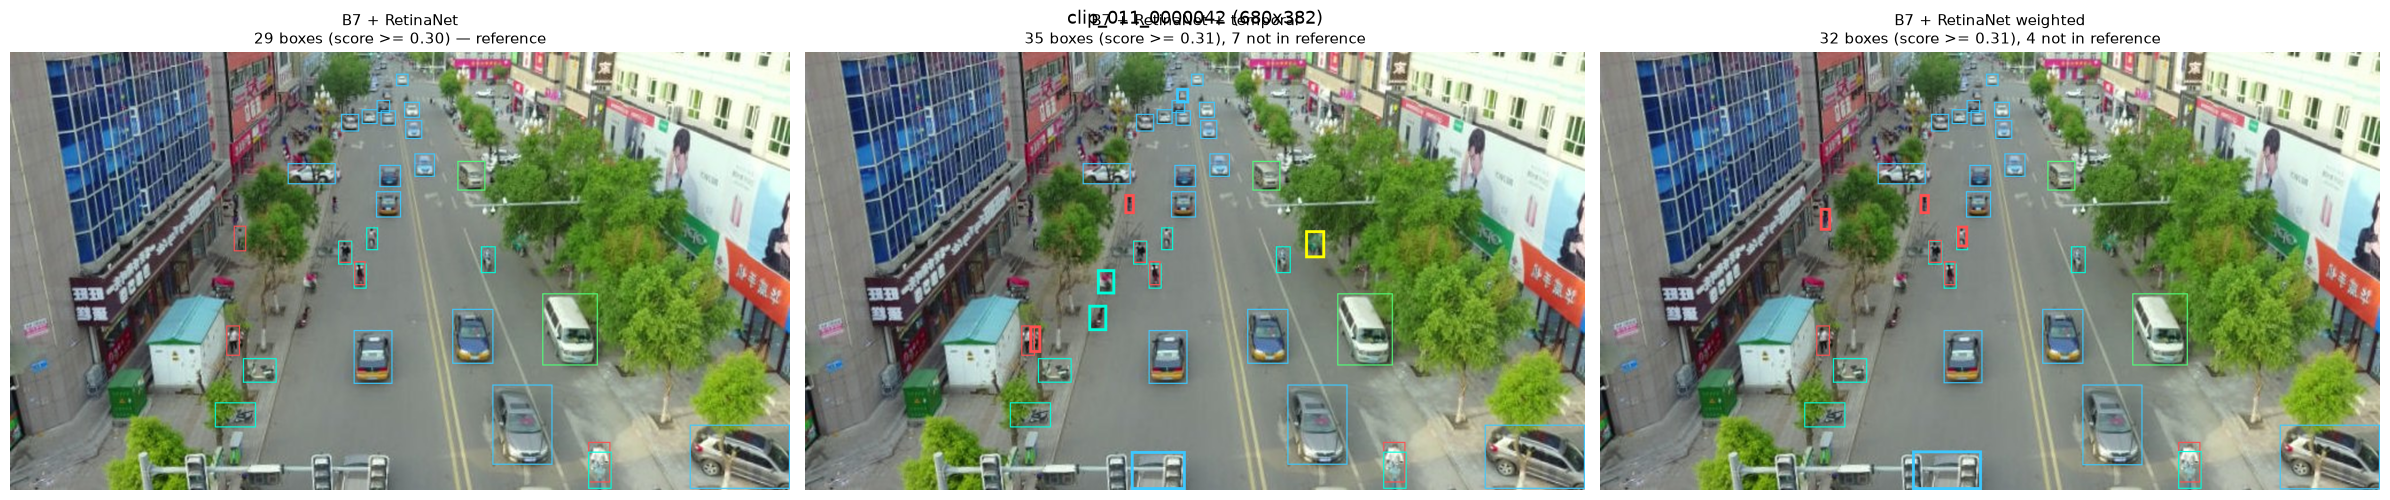

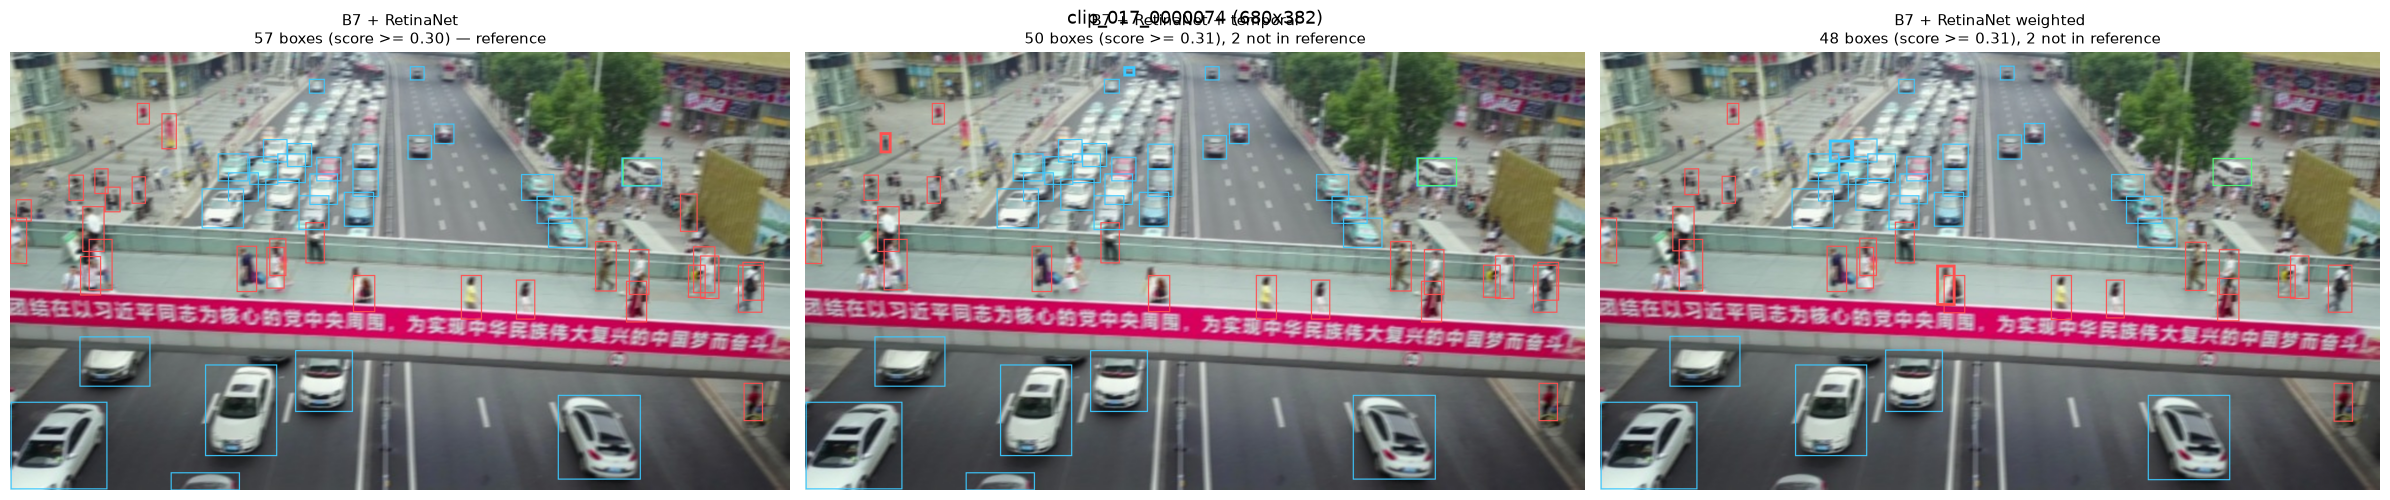

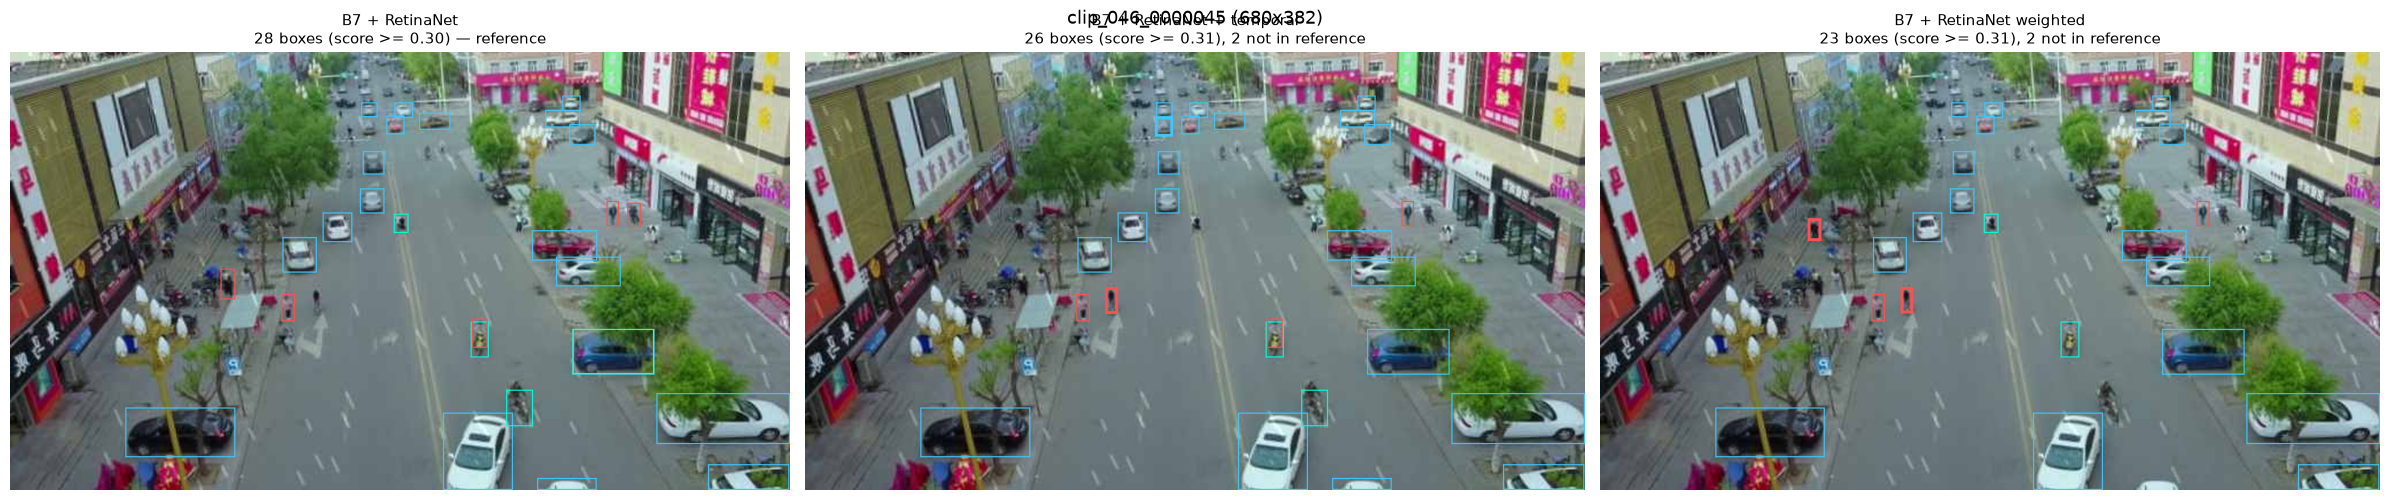

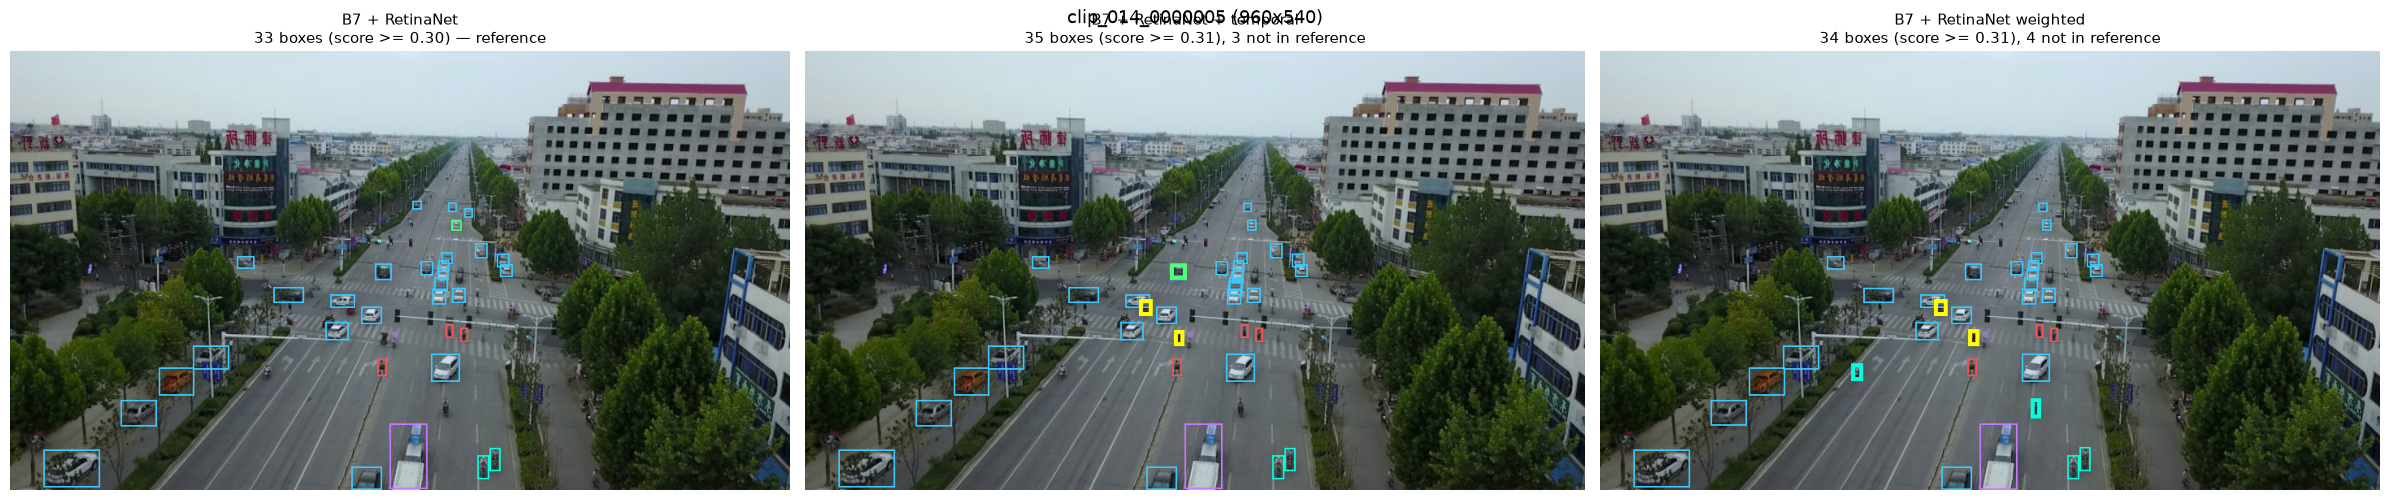

In [4]:
LOW_RES = clip_res[clip_res["width"] <= 960].index.tolist()
N_CLIPS = 4            # how many low-resolution clips to show (smallest first)


def disagreement(image_id):
    ref = shown(REFERENCE, image_id)
    return sum(int((~matched(shown(n, image_id), ref)).sum() + (~matched(ref, shown(n, image_id))).sum())
               for n in MAIN if n != REFERENCE)


picks = []
for clip in sorted(LOW_RES, key=lambda c: (clip_res.loc[c, "width"], c))[:N_CLIPS]:
    ids = test.loc[test["clip"] == clip, "image_id"].tolist()
    picks.append(max(ids, key=disagreement))

print("legend:", ", ".join(f"{c}={'#%02x%02x%02x' % COLOURS[i]}" for i, c in enumerate(CLASSES)))
for image_id in picks:
    clip = image_id.rsplit("_", 1)[0]
    scale = 2 if clip_res.loc[clip, "width"] <= 700 else 1
    panels = [draw(n, image_id, scale) for n in MAIN]
    fig, axes = plt.subplots(1, len(panels), figsize=(8 * len(panels), 8 * panels[0][0].height / panels[0][0].width + 0.6))
    for ax, n, (img, k, new) in zip(np.atleast_1d(axes), MAIN, panels):
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"{n}\n{k} boxes (score >= {THR[n]:.2f})" + (f", {new} not in reference" if n != REFERENCE else " — reference"), fontsize=11)
    fig.suptitle(f"{image_id} ({clip_res.loc[clip, 'width']}x{clip_res.loc[clip, 'height']})", fontsize=13)
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"main_{image_id}.jpg", dpi=110)
    plt.show()

**Observations:** _fill in_

## 3. All submissions on one frame

The low-resolution frame with the most disagreement from section 2 (change `FRAME` to look at another, e.g. `"clip_046_0000070"`).

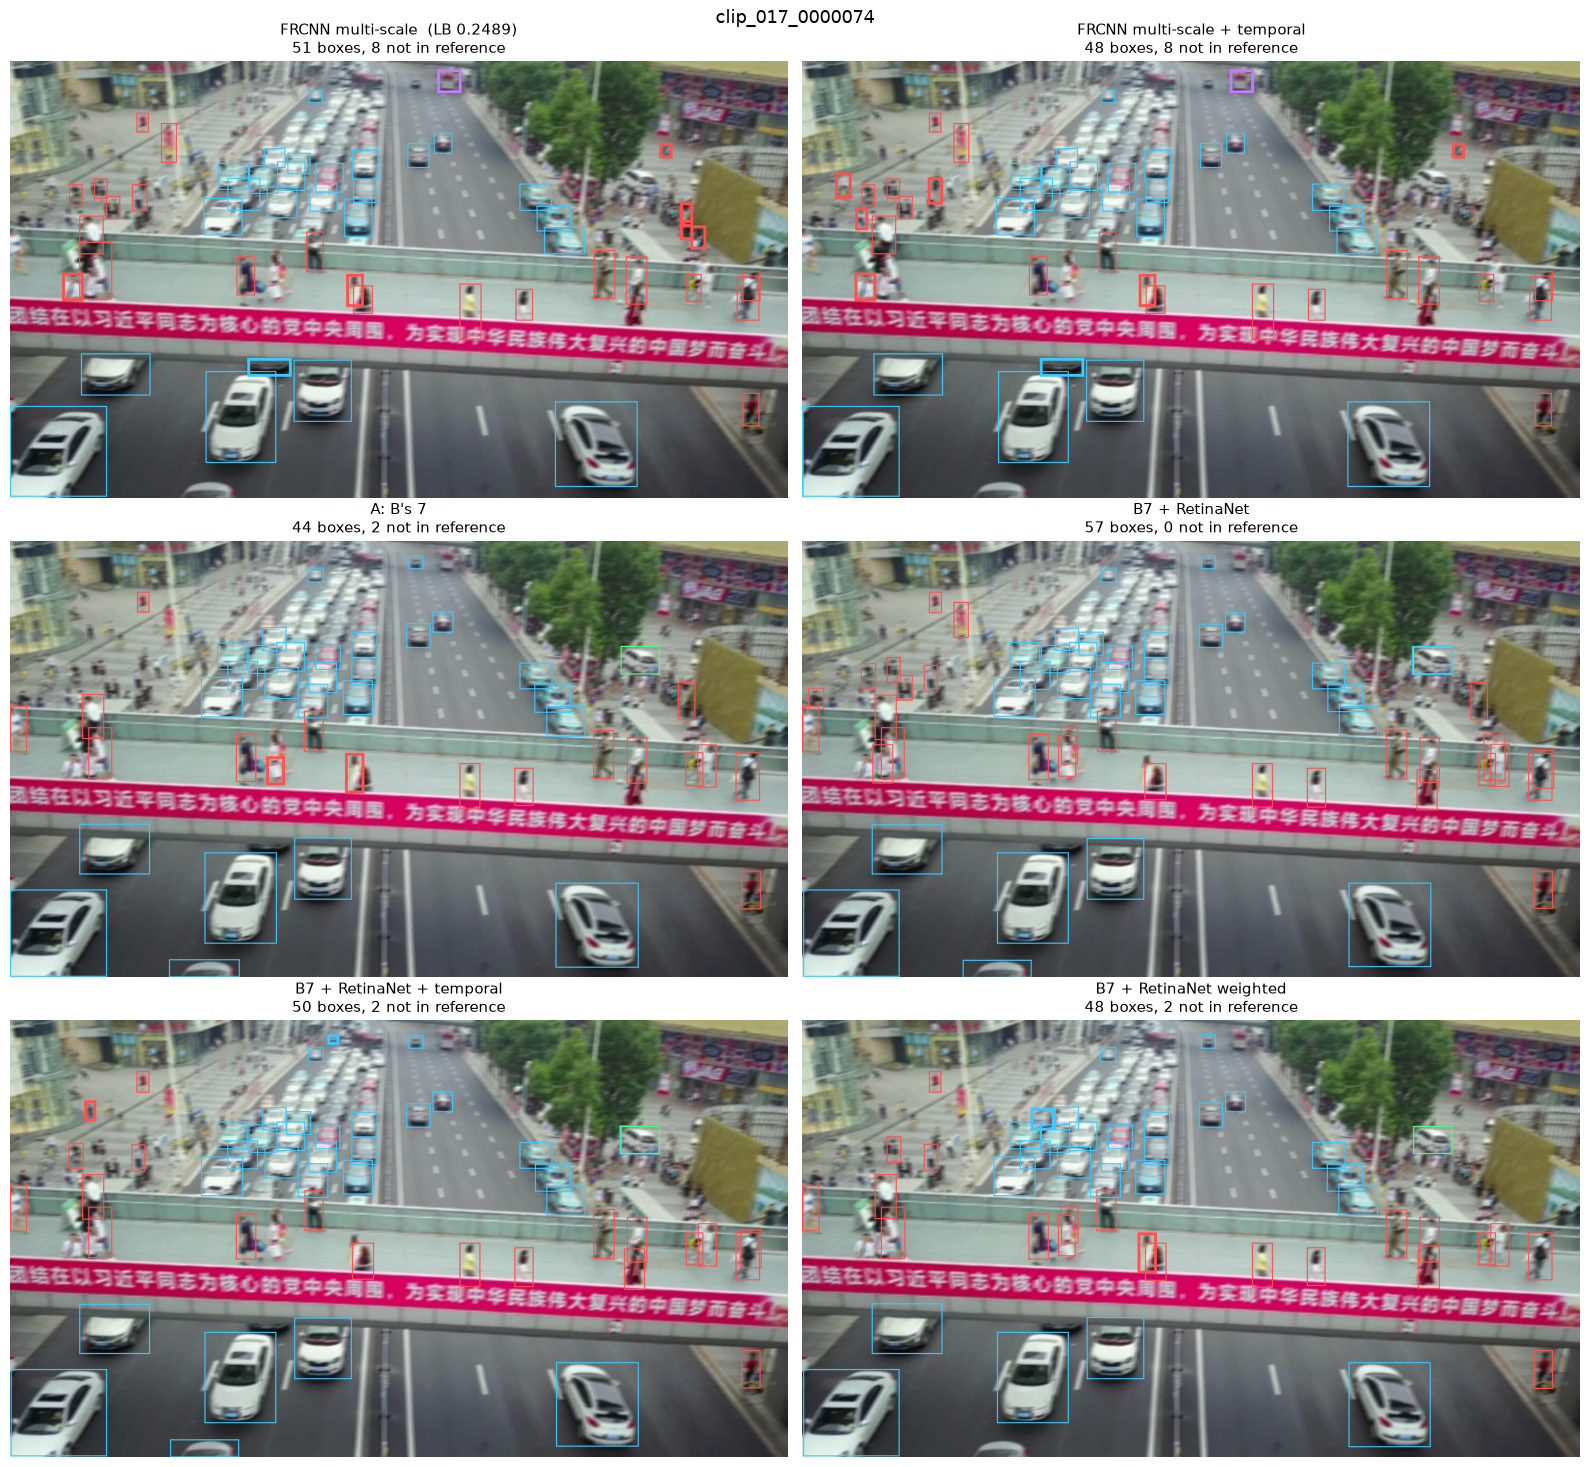

In [5]:
FRAME = max(picks, key=disagreement)
clip = FRAME.rsplit("_", 1)[0]
scale = 2 if clip_res.loc[clip, "width"] <= 700 else 1
names = list(SUBS)
cols = 2
rows_n = (len(names) + cols - 1) // cols
first = draw(names[0], FRAME, scale)[0]
fig, axes = plt.subplots(rows_n, cols, figsize=(16, rows_n * 8 * first.height / first.width + rows_n * 0.5))
axes = np.atleast_1d(axes).ravel()
for ax, n in zip(axes, names):
    img, k, new = draw(n, FRAME, scale)
    lb = SUBS[n][1]
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{n}{f'  (LB {lb:.4f})' if lb else ''}\n{k} boxes, {new} not in reference", fontsize=11)
for ax in axes[len(names):]:
    ax.axis("off")
fig.suptitle(FRAME, fontsize=13)
fig.tight_layout()
fig.savefig(OUT_DIR / f"all_{FRAME}.jpg", dpi=110)
plt.show()

## 4. Cross comparison in numbers

Per submission (at its equal-budget threshold): boxes per frame on all test frames and on the low-resolution clips, share of small boxes (area < 32² px), class mix. Then pairwise agreement on 400 random test frames: the share of the row submission's boxes that the column submission also has (same class, IoU ≥ 0.5).

In [6]:
low_ids = set(test.loc[test["clip"].isin(LOW_RES), "image_id"])
rows = []
for n in SUBS:
    allb = [shown(n, k) for k in test["image_id"]]
    cat = np.concatenate(allb)
    low = np.concatenate([b for k, b in zip(test["image_id"], allb) if k in low_ids])
    rows.append({"submission": n, "LB": SUBS[n][1], "threshold": THR[n], "boxes/frame": len(cat) / len(test),
                 "boxes/frame (low-res)": len(low) / len(low_ids),
                 "small %": 100 * float(((cat[:, 4] * cat[:, 5]) < 32 ** 2).mean()),
                 "small % (low-res)": 100 * float(((low[:, 4] * low[:, 5]) < 32 ** 2).mean()),
                 **{f"{c} %": 100 * float((cat[:, 0] == i).mean()) for i, c in enumerate(CLASSES)}})
pd.DataFrame(rows).set_index("submission").round(3)

,LB,threshold,boxes/frame,boxes/frame (low-res),small %,small % (low-res),person %,bicycle %,car %,van %,truck %,tricycle %,bus %,motor %
submission,,,,,,,,,,,,,,
FRCNN multi-scale,0.249,0.745,41.356,47.083,42.795,75.051,48.991,0.171,36.329,1.945,5.903,2.809,0.329,3.523
FRCNN multi-scale + temporal,NaN,0.743,41.355,46.095,42.167,73.757,48.226,0.159,37.054,2.119,5.924,2.773,0.374,3.372
A: B's 7,NaN,0.308,41.361,44.725,33.696,71.448,46.775,0.183,39.459,2.364,3.571,2.268,0.671,4.707
B7 + RetinaNet,NaN,0.300,41.354,45.240,33.856,71.286,46.327,0.196,39.298,2.504,3.860,2.413,0.678,4.723
B7 + RetinaNet + temporal,NaN,0.310,41.355,44.417,32.643,69.876,45.578,0.188,39.964,2.593,4.049,2.424,0.708,4.496
B7 + RetinaNet weighted,NaN,0.307,41.355,43.603,32.765,70.205,46.552,0.207,39.197,2.474,3.829,2.363,0.706,4.672


In [7]:
rng = np.random.default_rng(0)
sample = rng.choice(test["image_id"].to_numpy(), size=min(400, len(test)), replace=False)
names = list(SUBS)
agree = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        hit = tot = 0
        for k in sample:
            x = shown(a, k)
            hit += int(matched(x, shown(b, k)).sum()); tot += len(x)
        agree.loc[a, b] = hit / max(tot, 1)
agree.round(3)

,FRCNN multi-scale,FRCNN multi-scale + temporal,A: B's 7,B7 + RetinaNet,B7 + RetinaNet + temporal,B7 + RetinaNet weighted
FRCNN multi-scale,1.000,0.921,0.804,0.807,0.799,0.807
FRCNN multi-scale + temporal,0.923,1.000,0.811,0.813,0.814,0.814
A: B's 7,0.802,0.806,1.000,0.956,0.931,0.961
B7 + RetinaNet,0.809,0.812,0.960,1.000,0.945,0.967
B7 + RetinaNet + temporal,0.805,0.818,0.939,0.950,1.000,0.941
B7 + RetinaNet weighted,0.806,0.809,0.961,0.962,0.932,1.000


**Observations:** _fill in_